# American Option Pricing and Hedging in the CRR Binomial Tree

This notebook prices an American put in the Cox-Ross-Rubinstein (CRR) model by backward induction, studies the convergence of the price as the number of steps grows, and checks that the delta hedging strategy replicates the option exactly. It is based on a lab assignment in stochastic finance at Ensimag.

### Model

Horizon $T$, $N$ steps, $h = T/N$, $u = e^{\sigma\sqrt h}$, $d = e^{-\sigma\sqrt h}$, and one-period interest rate $1+R = e^{rh}$. The underlying follows
$$X_{n+1} = U_{n+1} X_n,\qquad X_0 = x,\qquad U_n \in\{u,d\}\ \text{i.i.d.},\qquad \mathbb P(U_n=u) = p = \frac{e^{rh}-d}{u-d}.$$
At step $n$, $X_n$ lives on $\chi_n = \{x\,u^i d^{n-i},\ 0\le i\le n\}$. Each node is indexed by its number of up moves $i$.

### Pricing recurrence

For a payoff $f$, the American price $P_N(n,y)$ at node $y\in\chi_n$ is defined by
$$P_N(N,y) = f(y),\qquad P_N(n-1,y) = \max\Big(f(y),\ e^{-rh}\big[p\,P_N(n,yu) + (1-p)\,P_N(n,yd)\big]\Big).\tag{1}$$
At each node, the holder compares immediate exercise $f(y)$ with the continuation value.

### Parameters

$X_0 = 100$, $K = 100$, $r = 0.03$, $\sigma = 0.2$, $T = 1$, with a put payoff $f(y) = (K-y)^+$. The reference value is $P_\infty(0,X_0) = 6.742984$. For comparison, the European put is worth about 6.46, and the American call on a non-dividend-paying stock equals the European call (about 9.41), so the early exercise premium only matters for the put.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

X0, K, r, sigma, T = 100.0, 100.0, 0.03, 0.2, 1.0
P_REF = 6.742984

def payoff_put(y, K=K):
    return np.maximum(K - y, 0.0)

def crr_params(N, r=r, sigma=sigma, T=T):
    h = T / N
    u, d = np.exp(sigma * np.sqrt(h)), np.exp(-sigma * np.sqrt(h))
    p = (np.exp(r * h) - d) / (u - d)
    return h, u, d, p

## 1. Why the recurrence gives the price

Let $Z_N = f(X_N)$ and $Z_{n-1} = \max\big(f(X_{n-1}),\ e^{-rh}\,\mathbb E[Z_n\mid\mathcal F_{n-1}]\big)$ be the Snell envelope of the payoff. We show by backward induction that $Z_n = P_N(n, X_n)$.

- **$n=N$**: $Z_N = f(X_N) = P_N(N, X_N)$.
- **$n \to n-1$**: assume $Z_n = P_N(n, X_n)$. Since $X_n = U_n X_{n-1}$, with $U_n$ independent of $\mathcal F_{n-1}$ and $X_{n-1}$ $\mathcal F_{n-1}$-measurable, the freezing lemma gives
$$\mathbb E[Z_n\mid \mathcal F_{n-1}] = p\,P_N(n, X_{n-1}u) + (1-p)\,P_N(n, X_{n-1}d).$$
Plugging this into the definition of $Z_{n-1}$ gives exactly $P_N(n-1, X_{n-1})$ from (1). The recurrence is well defined on the tree because $y\in\chi_{n-1}$ implies $yu, yd\in\chi_n$. $\square$

The conditional expectation only depends on $X_{n-1}$ (Markov property): thanks to the i.i.d. multiplicative structure, the current price is enough and the path history is irrelevant.

## 2. Backward induction

On $\chi_n$, node $i$ has successors $i+1$ (up) and $i$ (down). The tree is rolled back with vectorized operations: $O(N^2)$ time and $O(N)$ memory.

In [ ]:
def american_price(N, f=payoff_put, x=X0, r=r, sigma=sigma, T=T):
    # Price P_N(0, x) by backward induction
    h, u, d, p = crr_params(N, r, sigma, T)
    disc = np.exp(-r * h)
    i = np.arange(N + 1)
    P = f(x * u**i * d**(N - i))                       
    for n in range(N, 0, -1):
        i = np.arange(n)                              
        y = x * u**i * d**(n - 1 - i)
        cont = disc * (p * P[1:n + 1] + (1 - p) * P[0:n])
        P = np.maximum(f(y), cont)
    return P[0]

for N in [10, 100, 1000]:
    print(f"N = {N:5d}   P_N(0, X0) = {american_price(N):.6f}")
print(f"Reference    P_inf     = {P_REF:.6f}")

N =    10   P_N(0, X0) = 6.642500
N =   100   P_N(0, X0) = 6.733180
N =  1000   P_N(0, X0) = 6.742045
Reference    P_inf     = 6.742984


## 3. Convergence in $N$

We expect $N\,(P_N(0,X_0) - P_\infty(0,X_0)) \to a$, i.e. $P_N \approx P_\infty + a/N$. Regressing $P_N$ on $1/N$ gives an estimate of $a$ (slope) and an extrapolated estimate of $P_\infty$ (intercept).

In [3]:
Ns = np.array([10, 100, 200, 500, 600, 800, 1000, 2000, 3000, 4000, 5000, 6000, 8000, 10000])
prices = np.array([american_price(N) for N in Ns])
err = prices - P_REF

print(f"{'N':>6} {'P_N':>12} {'P_N - P_ref':>14} {'N (P_N - P_ref)':>18}")
for N, P, e in zip(Ns, prices, err):
    print(f"{N:6d} {P:12.6f} {e:14.2e} {N * e:18.5f}")

     N          P_N    P_N - P_ref    N (P_N - P_ref)
    10     6.642500      -1.00e-01           -1.00484
   100     6.733180      -9.80e-03           -0.98043
   200     6.738201      -4.78e-03           -0.95664
   500     6.741085      -1.90e-03           -0.94950
   600     6.741409      -1.57e-03           -0.94471
   800     6.741810      -1.17e-03           -0.93941
  1000     6.742045      -9.39e-04           -0.93930
  2000     6.742521      -4.63e-04           -0.92646
  3000     6.742678      -3.06e-04           -0.91666
  4000     6.742756      -2.28e-04           -0.91147
  5000     6.742803      -1.81e-04           -0.90413
  6000     6.742835      -1.49e-04           -0.89675
  8000     6.742874      -1.10e-04           -0.88188
 10000     6.742897      -8.68e-05           -0.86817


Slope a ≈ -1.0053   intercept b ≈ 6.743060   (reference 6.742984)
Without N = 10: a ≈ -0.9786   b ≈ 6.743016


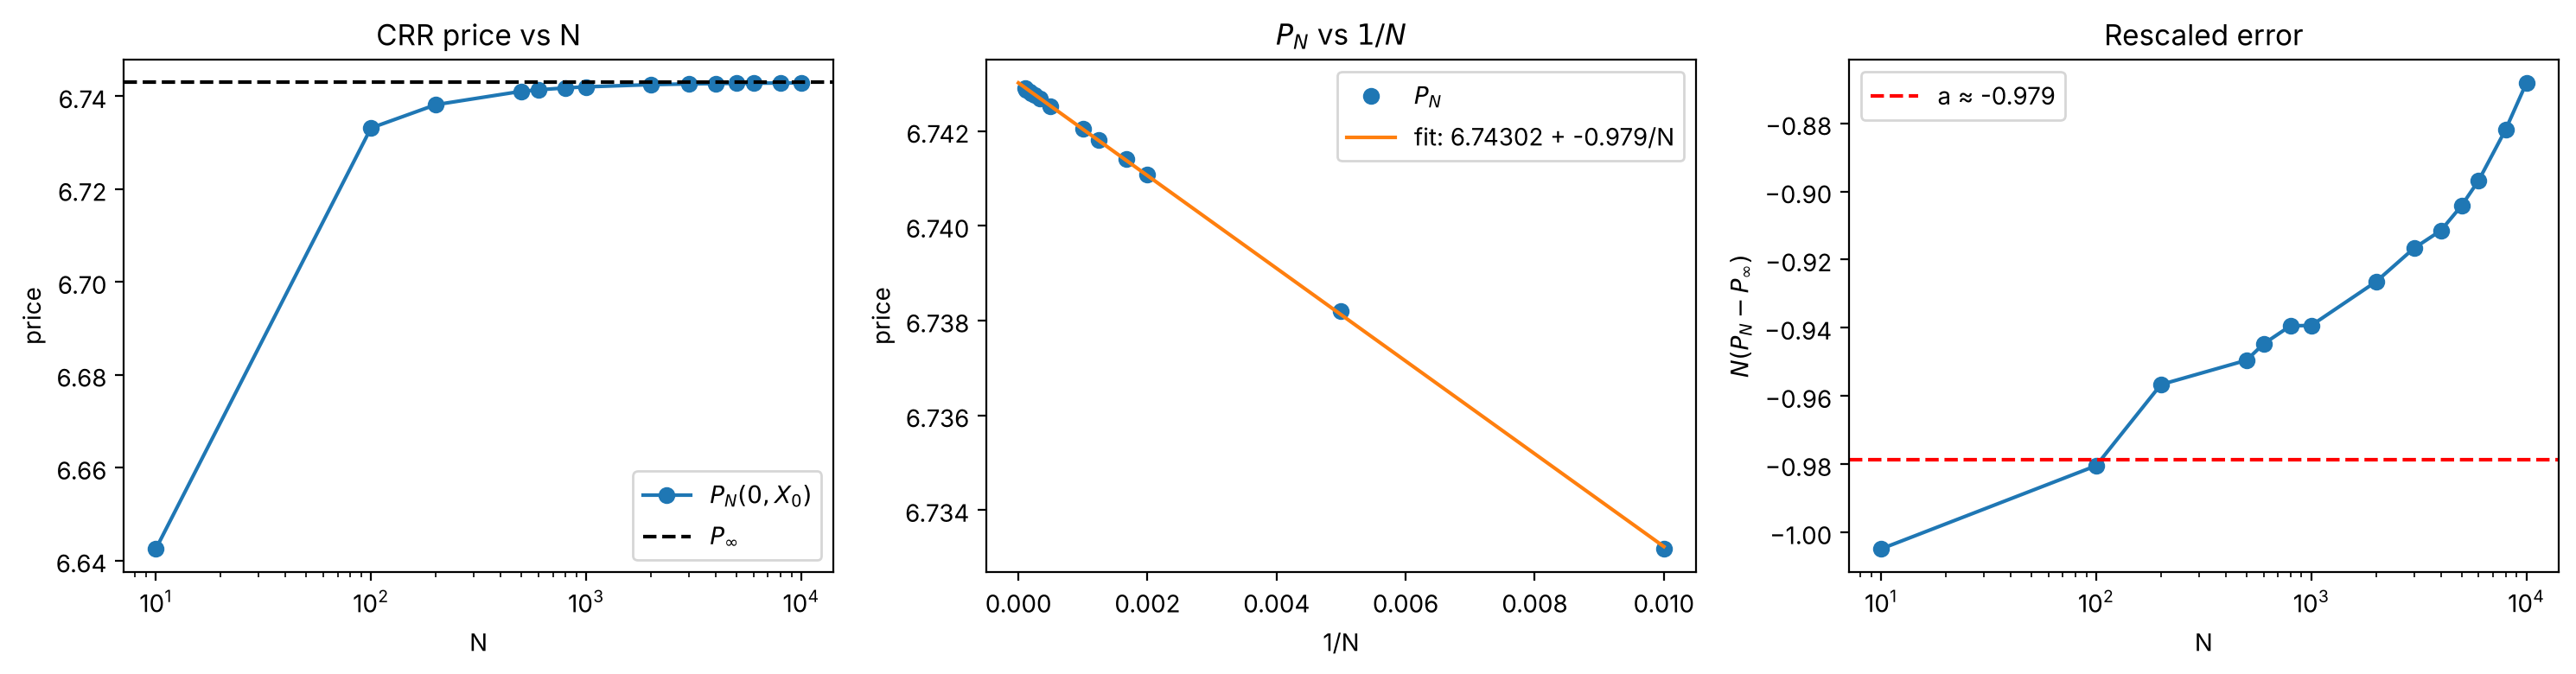

In [ ]:
# Linear regression P_N = b + a / N
A = np.vstack([np.ones_like(Ns, dtype=float), 1.0 / Ns]).T
(b, a), *_ = np.linalg.lstsq(A, prices, rcond=None)
print(f"Slope a ≈ {a:.4f}   intercept b ≈ {b:.6f}   (reference {P_REF})")

# Same regression without N = 10
mask = Ns >= 100
(b2, a2), *_ = np.linalg.lstsq(A[mask], prices[mask], rcond=None)
print(f"Without N = 10: a ≈ {a2:.4f}   b ≈ {b2:.6f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].semilogx(Ns, prices, "o-", label="$P_N(0,X_0)$")
ax[0].axhline(P_REF, color="k", ls="--", label="$P_\\infty$")
ax[0].set(xlabel="N", ylabel="price", title="CRR price vs N"); ax[0].legend()

ax[1].plot(1 / Ns[mask], prices[mask], "o", label="$P_N$")
xx = np.linspace(0, 1 / Ns[mask].min(), 50)
ax[1].plot(xx, b2 + a2 * xx, "-", label=f"fit: {b2:.5f} + {a2:.3f}/N")
ax[1].set(xlabel="1/N", ylabel="price", title="$P_N$ vs $1/N$"); ax[1].legend()

ax[2].semilogx(Ns, Ns * err, "o-")
ax[2].axhline(a2, color="r", ls="--", label=f"a ≈ {a2:.3f}")
ax[2].set(xlabel="N", ylabel="$N(P_N - P_\\infty)$", title="Rescaled error"); ax[2].legend()
plt.tight_layout(); plt.show()

$N(P_N - P_\infty)$ stays bounded, close to $-0.9$ to $-1$: convergence is of order $1/N$, from below. The slow drift at large $N$ mostly comes from the precision of the reference value, since an error $\delta$ on $P_\infty$ adds $N\delta$ to the rescaled error (0.1 at $N=10^4$ for $\delta=10^{-5}$). The regression indeed suggests $P_\infty \approx 6.74302$, a few $10^{-5}$ away from the given value. Since $P_N$ is almost linear in $1/N$, the intercept recovers $P_\infty$ to several digits. This is the idea behind Richardson extrapolation: $2P_{2N} - P_N$ removes the $1/N$ term.

The $1/N$ rate is expected: the CRR tree is a discretization of the Black-Scholes PDE with step $h = T/N$, and with a payoff that has a kink at the strike, the leading error is of order $h$. The small residual irregularities come from the position of the strike relative to the grid (which depends on the parity of $N$) and from the exercise boundary.

## 4. Delta hedging formula

Take $y\in\chi_{n-1}$ where it is not optimal to exercise. The seller must then replicate $P(n, X_n)$ in both possible states at time $n$. The strategy $(\varphi^0_n,\varphi_n)$ (cash, stock) is predictable: it is chosen at time $n-1$, knowing $X_{n-1} = y$. Replication in the two states $X_n = yu$ and $X_n = yd$ gives
$$\begin{cases}\varphi^0_n(1+R)^n + \varphi_n\, yu = P(n, yu)\\[2pt] \varphi^0_n(1+R)^n + \varphi_n\, yd = P(n, yd)\end{cases}$$
Subtracting the two equations:
$$\varphi(n,y) = \frac{P(n,yu) - P(n,yd)}{y(u-d)},\qquad \varphi^0_n = \frac{P(n,yu) - \varphi(n,y)\,yu}{(1+R)^n}.\tag{2}$$
The delta is the slope of the option value between the two successor nodes.

**Self-financing check.** The value of this portfolio at time $n-1$ is $\varphi^0_n(1+R)^{n-1} + \varphi_n y$. With $p = \frac{(1+R)-d}{u-d}$, a direct computation shows it equals $\frac{1}{1+R}\big[pP(n,yu) + (1-p)P(n,yd)\big]$, i.e. the continuation value, which is $P(n-1,y)$ since we do not exercise at $y$. Setting up the hedge costs exactly the current option value.

## 5. Hedging along a simulated path

We store the full grid $P(n,\cdot)$ ($O(N^2)$ memory, fine for moderate $N$). The optimal (smallest) stopping time is
$$\tau^* = \inf\{n\ge 0 : P(n, X_n) = f(X_n)\}\ \le N.$$
Starting from $V_0 = P(0,x)$, for $n = 1,\dots,\tau^*$:
1. $\varphi_n = \varphi(n, X_{n-1})$ and $\varphi^0_n = \dfrac{V_{n-1} - \varphi_n X_{n-1}}{(1+R)^{n-1}}$ (rebalance without adding or withdrawing cash);
2. $V_n = \varphi^0_n(1+R)^n + \varphi_n X_n$.

At $\tau^*$, the option is exercised and the seller delivers $f(X_{\tau^*})$. On a path that ends far out of the money near maturity, the continuation value can drop to zero, so $P = f = 0$ and $\tau^*$ stops there with a zero payoff and a zero portfolio.

In [ ]:
def american_grid(N, f=payoff_put, x=X0, r=r, sigma=sigma, T=T):
    h, u, d, p = crr_params(N, r, sigma, T)
    disc = np.exp(-r * h)
    P, ex = [None] * (N + 1), [None] * (N + 1)
    i = np.arange(N + 1)
    P[N] = f(x * u**i * d**(N - i))
    ex[N] = np.ones(N + 1, dtype=bool)
    for n in range(N, 0, -1):
        i = np.arange(n)
        y = x * u**i * d**(n - 1 - i)
        cont = disc * (p * P[n][1:] + (1 - p) * P[n][:-1])
        fy = f(y)
        P[n - 1] = np.maximum(fy, cont)
        ex[n - 1] = fy >= cont - 1e-12 
    return P, ex, (h, u, d, p)


def simulate_path(N, p, rng):
    ups = rng.random(N) < p
    return np.concatenate([[0], np.cumsum(ups)])


def delta_hedge(N, idx, grid, x=X0, r=r):
    P, ex, (h, u, d, p) = grid
    G = np.exp(r * h)
    X = lambda n: x * u**idx[n] * d**(n - idx[n])

    tau = next(n for n in range(N + 1) if ex[n][idx[n]])
    V = np.empty(tau + 1); V[0] = P[0][0]
    phi, phi0 = np.full(tau + 1, np.nan), np.full(tau + 1, np.nan)
    for n in range(1, tau + 1):
        i, y = idx[n - 1], X(n - 1)
        phi[n] = (P[n][i + 1] - P[n][i]) / (y * (u - d))   
        phi0[n] = (V[n - 1] - phi[n] * y) / G**(n - 1)    
        V[n] = phi0[n] * G**n + phi[n] * X(n)
    Xpath = np.array([X(n) for n in range(tau + 1)])
    Ppath = np.array([P[n][idx[n]] for n in range(tau + 1)])
    return dict(tau=tau, X=Xpath, V=V, P=Ppath, phi=phi, phi0=phi0)


N_h = 200
grid = american_grid(N_h)
rng = np.random.default_rng(0)
res = delta_hedge(N_h, simulate_path(N_h, grid[2][3], rng), grid)

print(f"tau* = {res['tau']}  (out of N = {N_h})")
print(f"V_tau* = {res['V'][-1]:.10f}   f(X_tau*) = {payoff_put(res['X'][-1]):.10f}")
print(f"max_n |V_n - P(n, X_n)| = {np.max(np.abs(res['V'] - res['P'])):.2e}")

tau* = 116  (out of N = 200)
V_tau* = 17.9621860045   f(X_tau*) = 17.9621860045
max_n |V_n - P(n, X_n)| = 1.53e-13


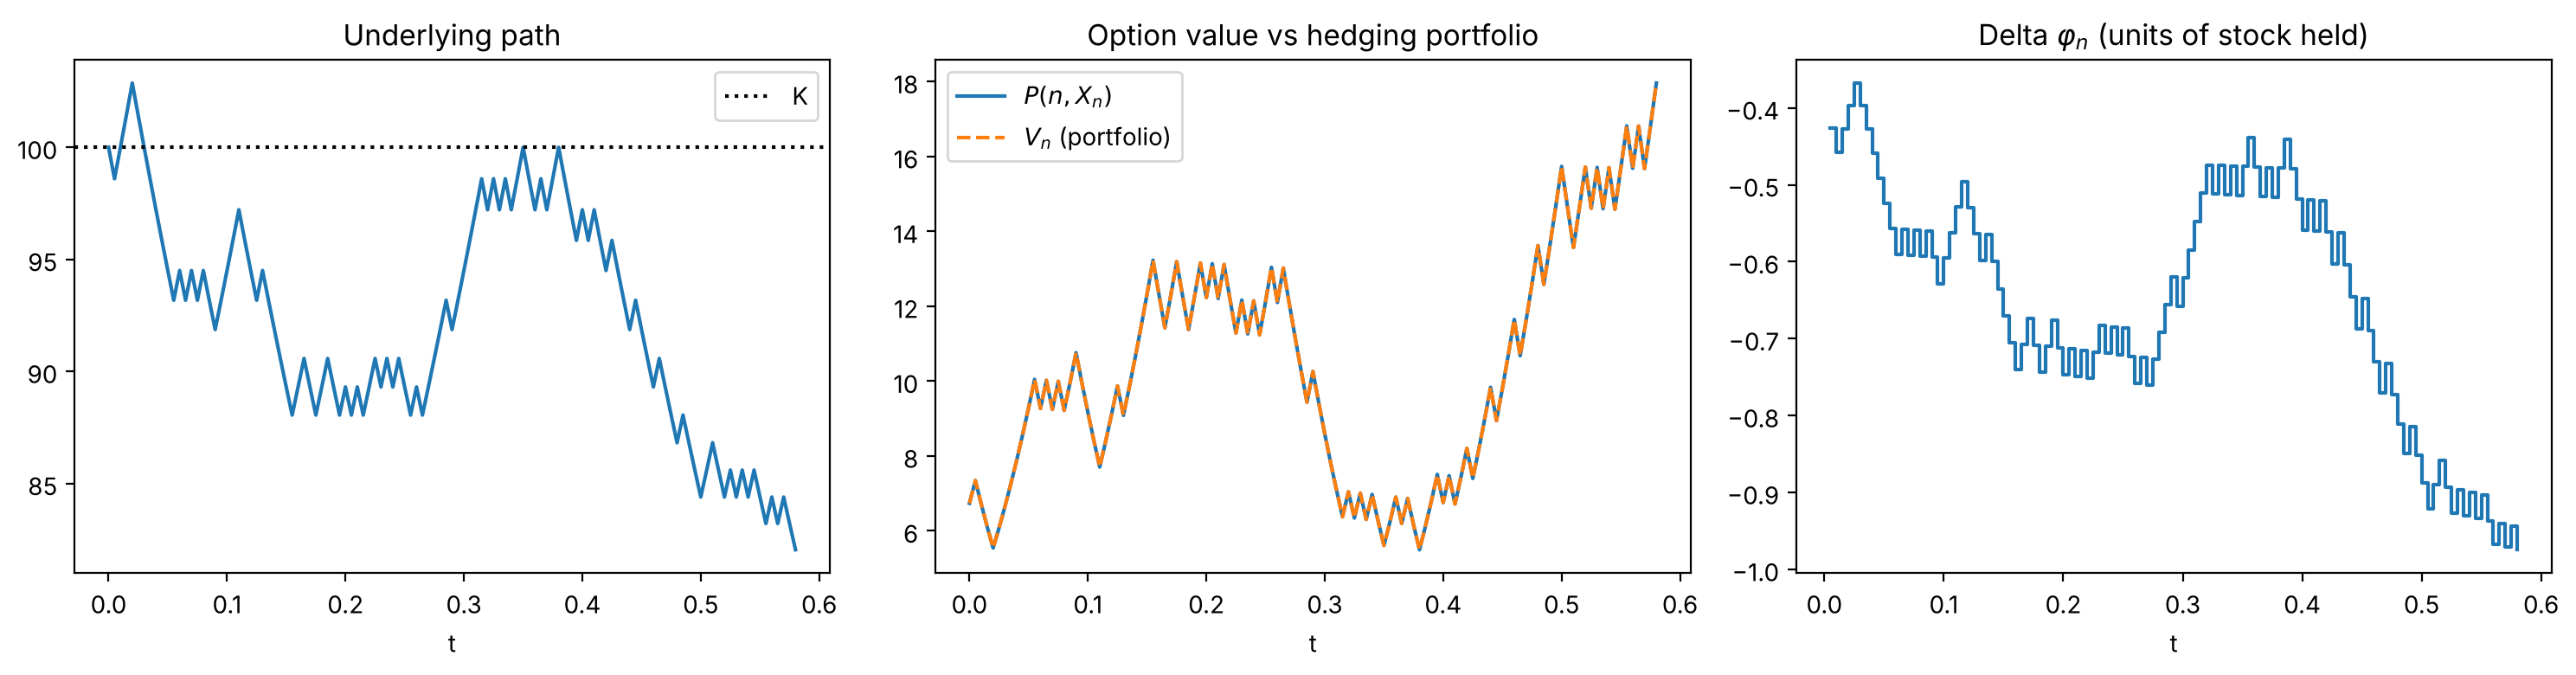

In [6]:
t = np.arange(res["tau"] + 1) * grid[2][0]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(t, res["X"]); ax[0].axhline(K, color="k", ls=":", label="K")
ax[0].set(title="Underlying path", xlabel="t"); ax[0].legend()
ax[1].plot(t, res["P"], label="$P(n, X_n)$")
ax[1].plot(t, res["V"], "--", label="$V_n$ (portfolio)")
ax[1].set(title="Option value vs hedging portfolio", xlabel="t"); ax[1].legend()
ax[2].step(t[1:], res["phi"][1:], where="post")
ax[2].set(title="Delta $\\varphi_n$ (units of stock held)", xlabel="t")
plt.tight_layout(); plt.show()

The portfolio tracks the option value exactly. The delta of a put lies in $[-1, 0]$, so the hedge is a short position in the stock. It moves towards $-1$ as the stock falls towards the exercise region, and towards 0 as the option goes out of the money.

## 6. Zero quadratic hedging error

We estimate $\mathbb E\big[(V_{\tau^*} - f(X_{\tau^*}))^2\big]$ by Monte Carlo. The CRR market is complete (two states per step, two assets), so replication is exact path by path and the error should be zero up to floating-point rounding. For the same reason, the result does not depend on the probability used to simulate the paths: we check it under both the risk-neutral $p$ and a historical $p = 0.45$.

In [7]:
def hedging_error(N, M, p_sim, seed=1):
    grid = american_grid(N)
    rng = np.random.default_rng(seed)
    errs, taus, itm = np.empty(M), np.empty(M, dtype=int), np.empty(M, dtype=bool)
    for m in range(M):
        res = delta_hedge(N, simulate_path(N, p_sim, rng), grid)
        fx = payoff_put(res["X"][-1])
        errs[m], taus[m], itm[m] = res["V"][-1] - fx, res["tau"], fx > 0
    return errs, taus, itm

N_h, M = 200, 5000
p_rn = crr_params(N_h)[3]
for name, ps in [("risk-neutral p", p_rn), ("historical p = 0.45", 0.45)]:
    errs, taus, itm = hedging_error(N_h, M, ps)
    print(f"{name:22s}  E[(V_tau - f(X_tau))^2] = {np.mean(errs**2):.2e}   "
          f"max |error| = {np.max(np.abs(errs)):.2e}   "
          f"early exercise in the money: {np.mean((taus < N_h) & itm):.1%}")

risk-neutral p          E[(V_tau - f(X_tau))^2] = 4.75e-27   max |error| = 8.10e-13   early exercise in the money: 49.5%


historical p = 0.45     E[(V_tau - f(X_tau))^2] = 5.11e-27   max |error| = 3.69e-13   early exercise in the money: 92.7%


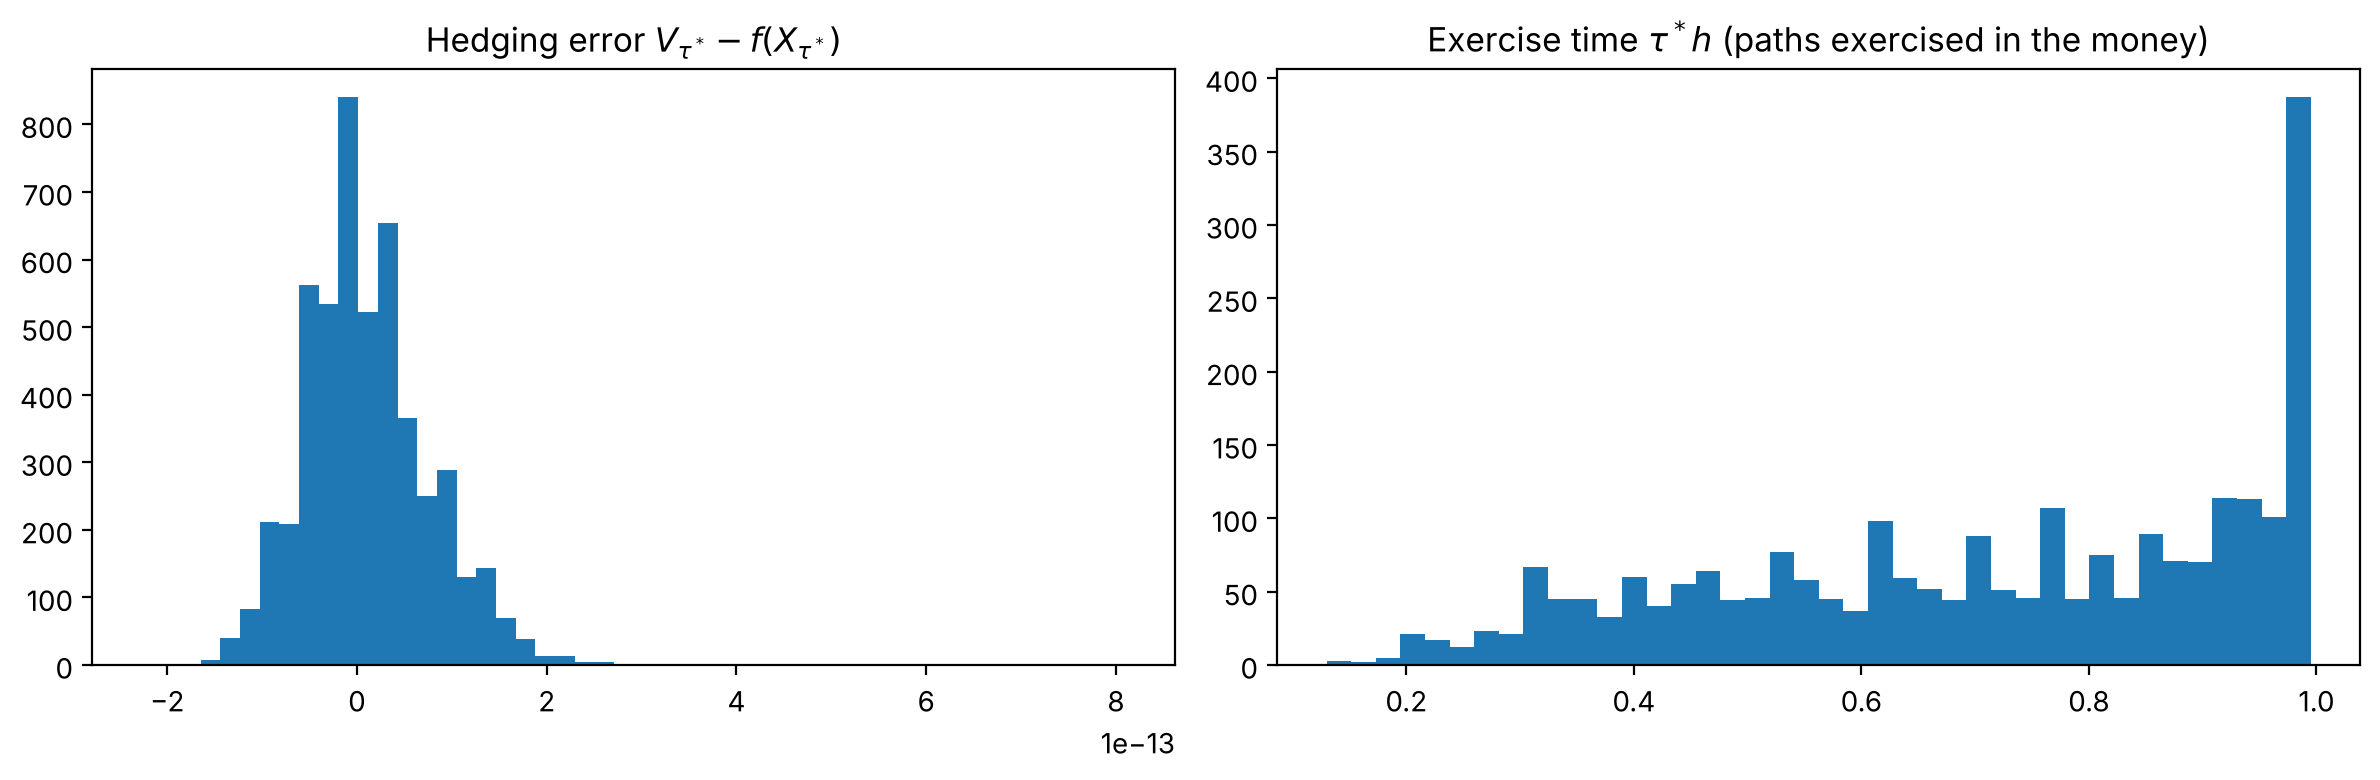

In [8]:
errs, taus, itm = hedging_error(N_h, M, p_rn)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(errs, bins=50); ax[0].set(title="Hedging error $V_{\\tau^*} - f(X_{\\tau^*})$")
ax[1].hist(taus[itm] * grid[2][0], bins=40)
ax[1].set(title="Exercise time $\\tau^* h$ (paths exercised in the money)")
plt.tight_layout(); plt.show()

The mean squared error is around $10^{-27}$, which is floating-point noise: the self-financing delta strategy (2), started with capital $P(0, X_0)$, replicates the American payoff exactly at the optimal exercise time $\tau^*$.

The reason is that before $\tau^*$, $P(n-1, X_{n-1}) > f(X_{n-1})$, so the option value is the continuation value, which can be replicated over one step (Section 4). If the holder exercised suboptimally, after $\tau^*$ in the region where $P = f >$ continuation value, the seller would even make a profit of $f - \text{continuation} \ge 0$. The hedge therefore super-replicates the option for any stopping time.